data.pq loaded successfully: 1173 rows, 154 columns.
ir_prediction_data.pq loaded successfully: 1165 rows, 155 columns.


/tmp/ipykernel_1034/2667503525.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_ir, x='hypertension_binary', palette='Set2', ax=ax1)


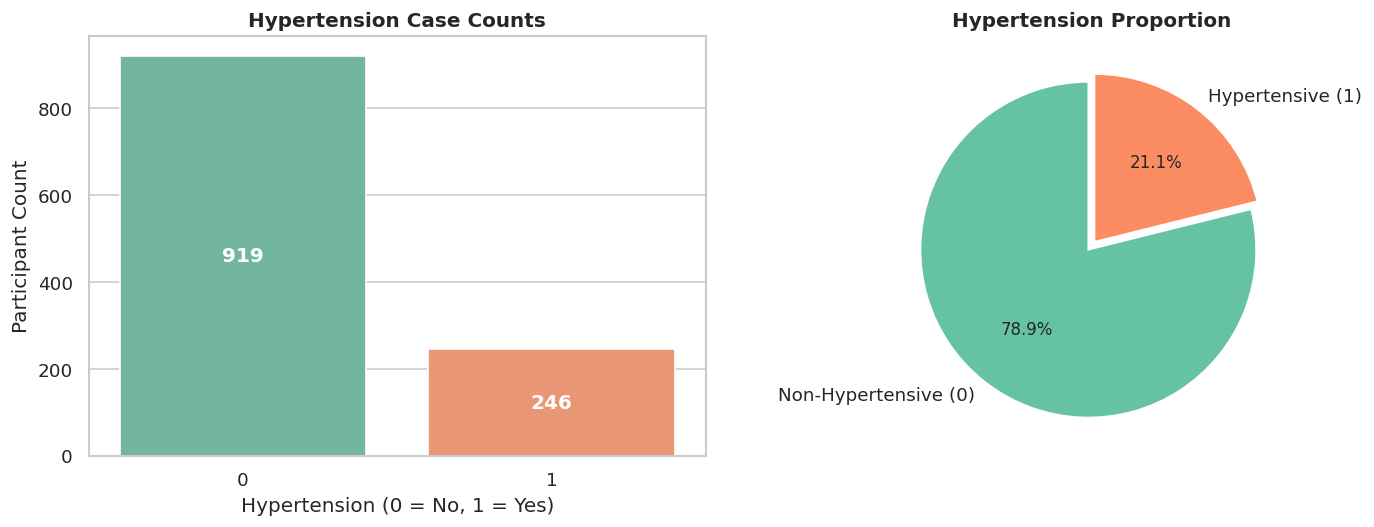

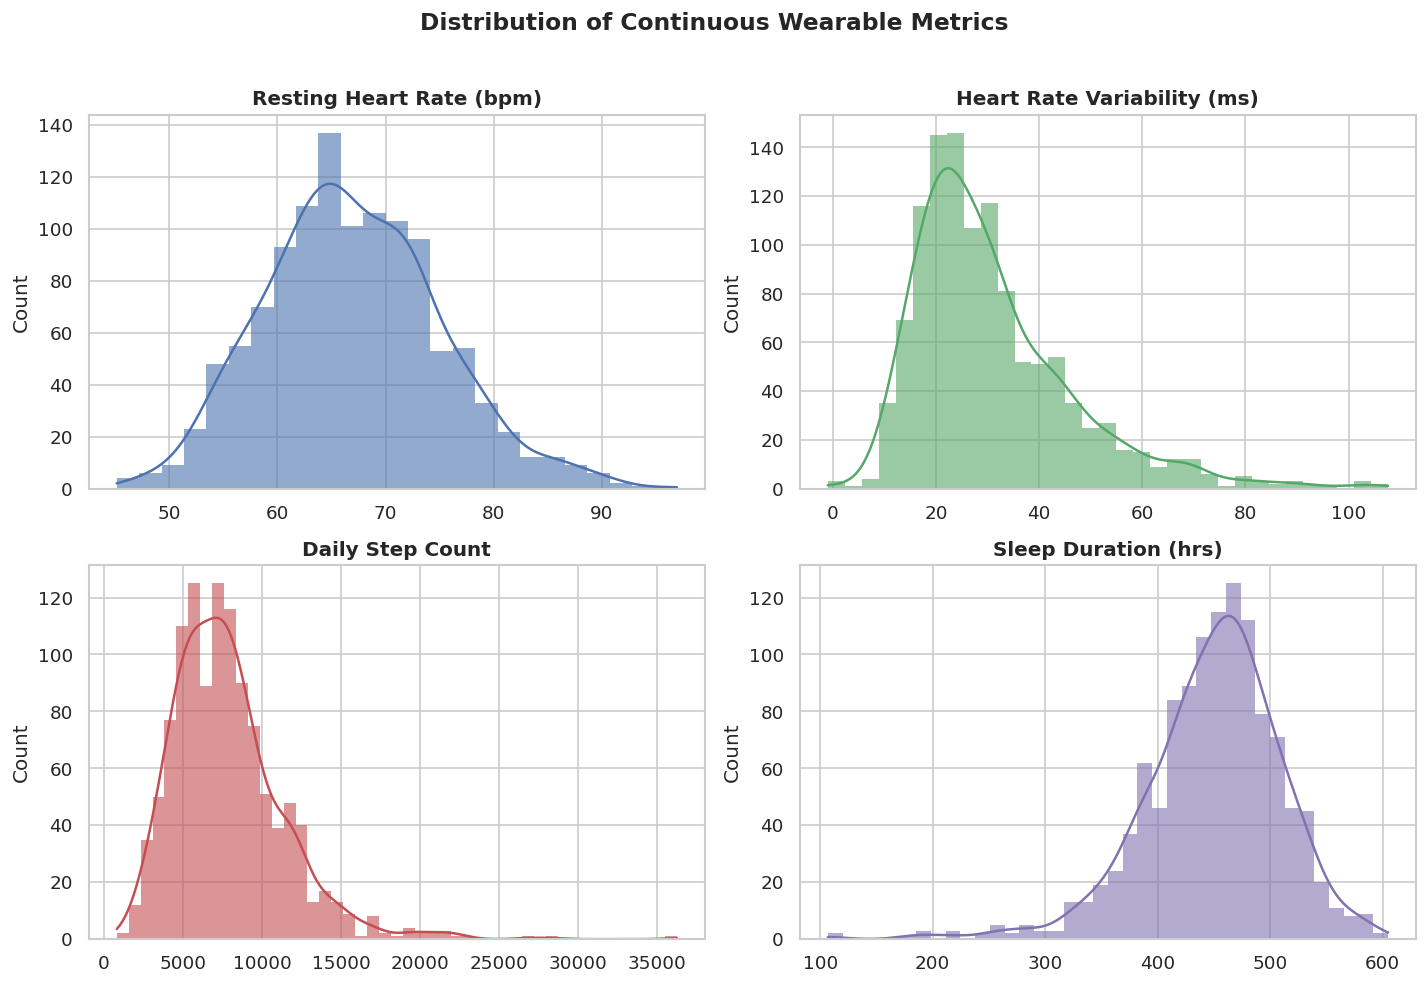

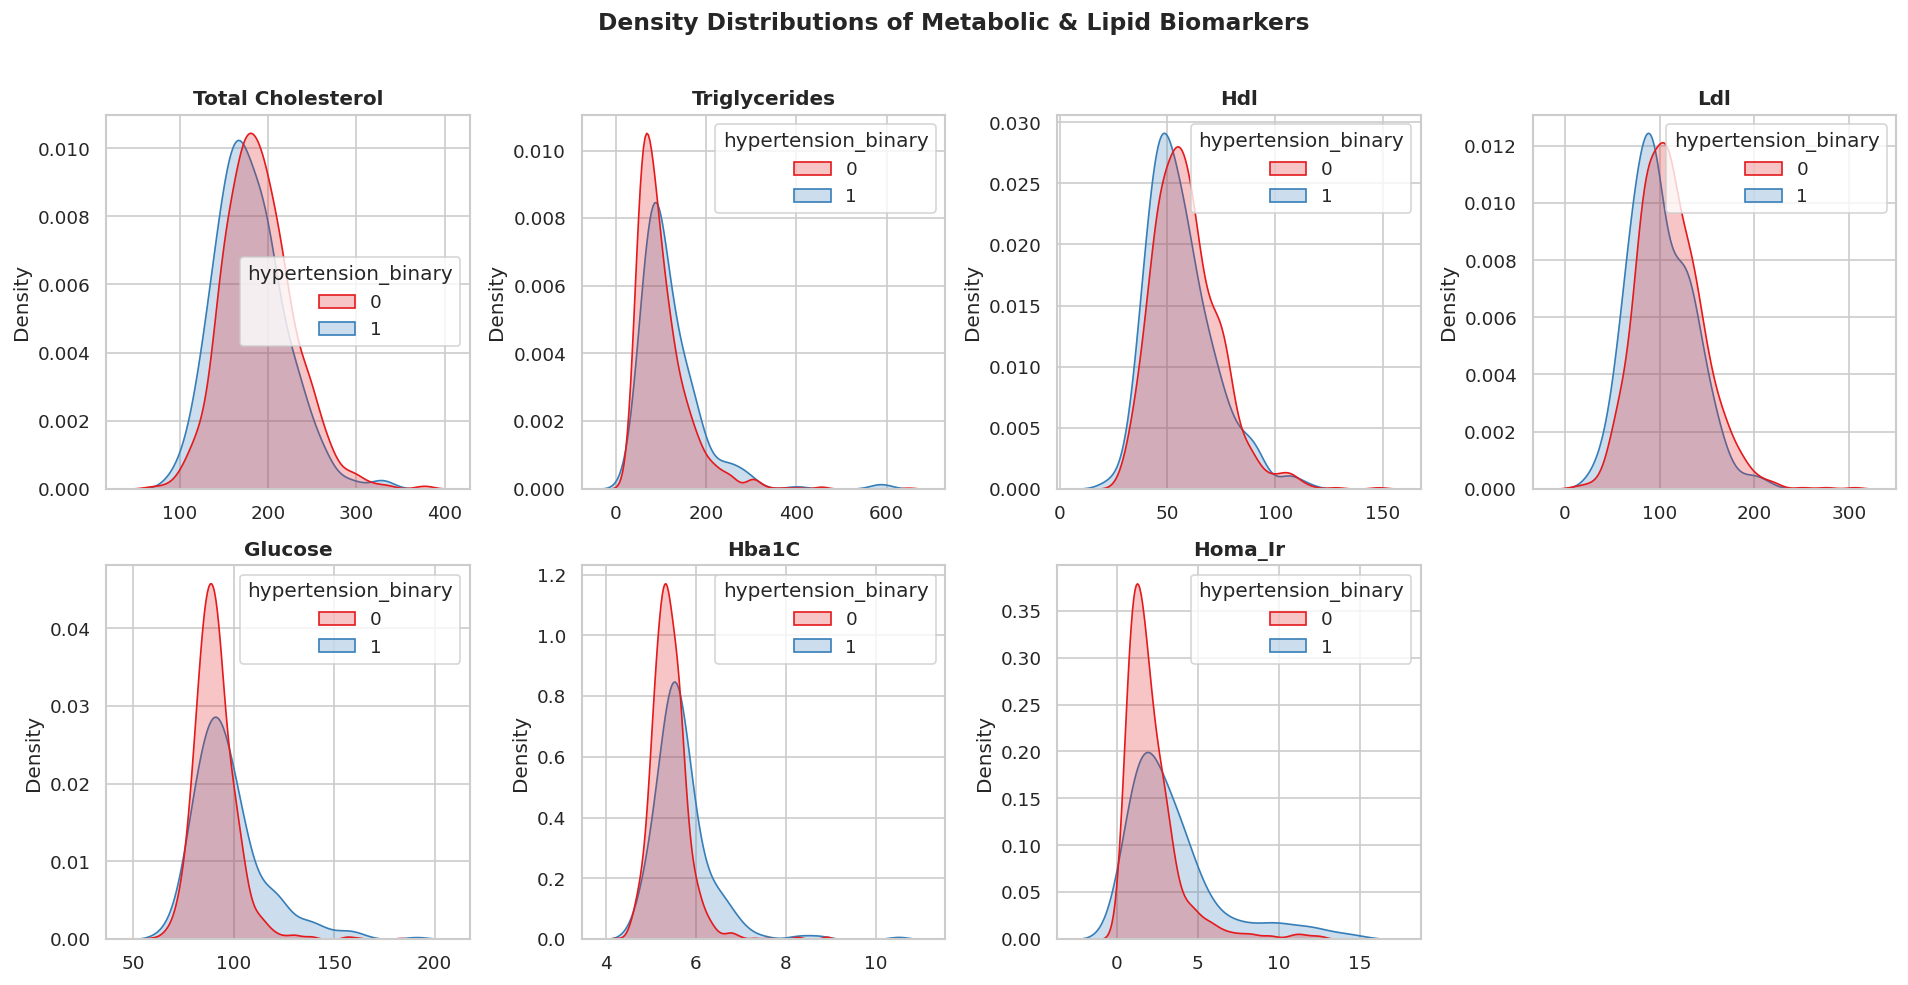

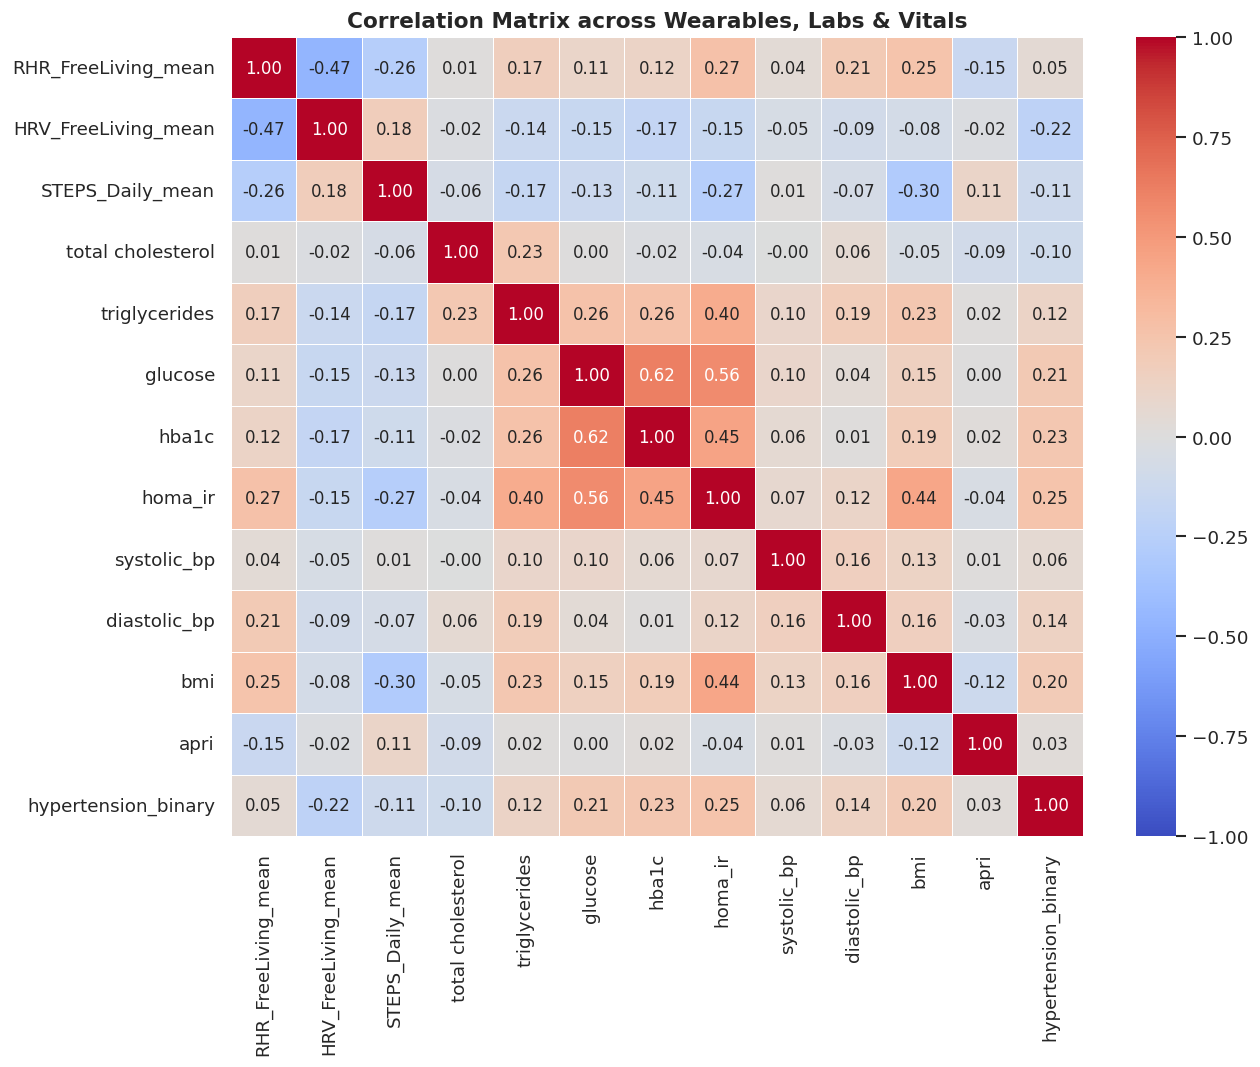

/tmp/ipykernel_1034/2667503525.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ir, x='hypertension_binary', y=col, palette='Set2', ax=axes[i], showmeans=True)
/tmp/ipykernel_1034/2667503525.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ir, x='hypertension_binary', y=col, palette='Set2', ax=axes[i], showmeans=True)
/tmp/ipykernel_1034/2667503525.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_ir, x='hypertension_binary', y=col, palette='Set2', ax=axes[i], showmeans=True)
/tmp/ipykernel_1034/26675035

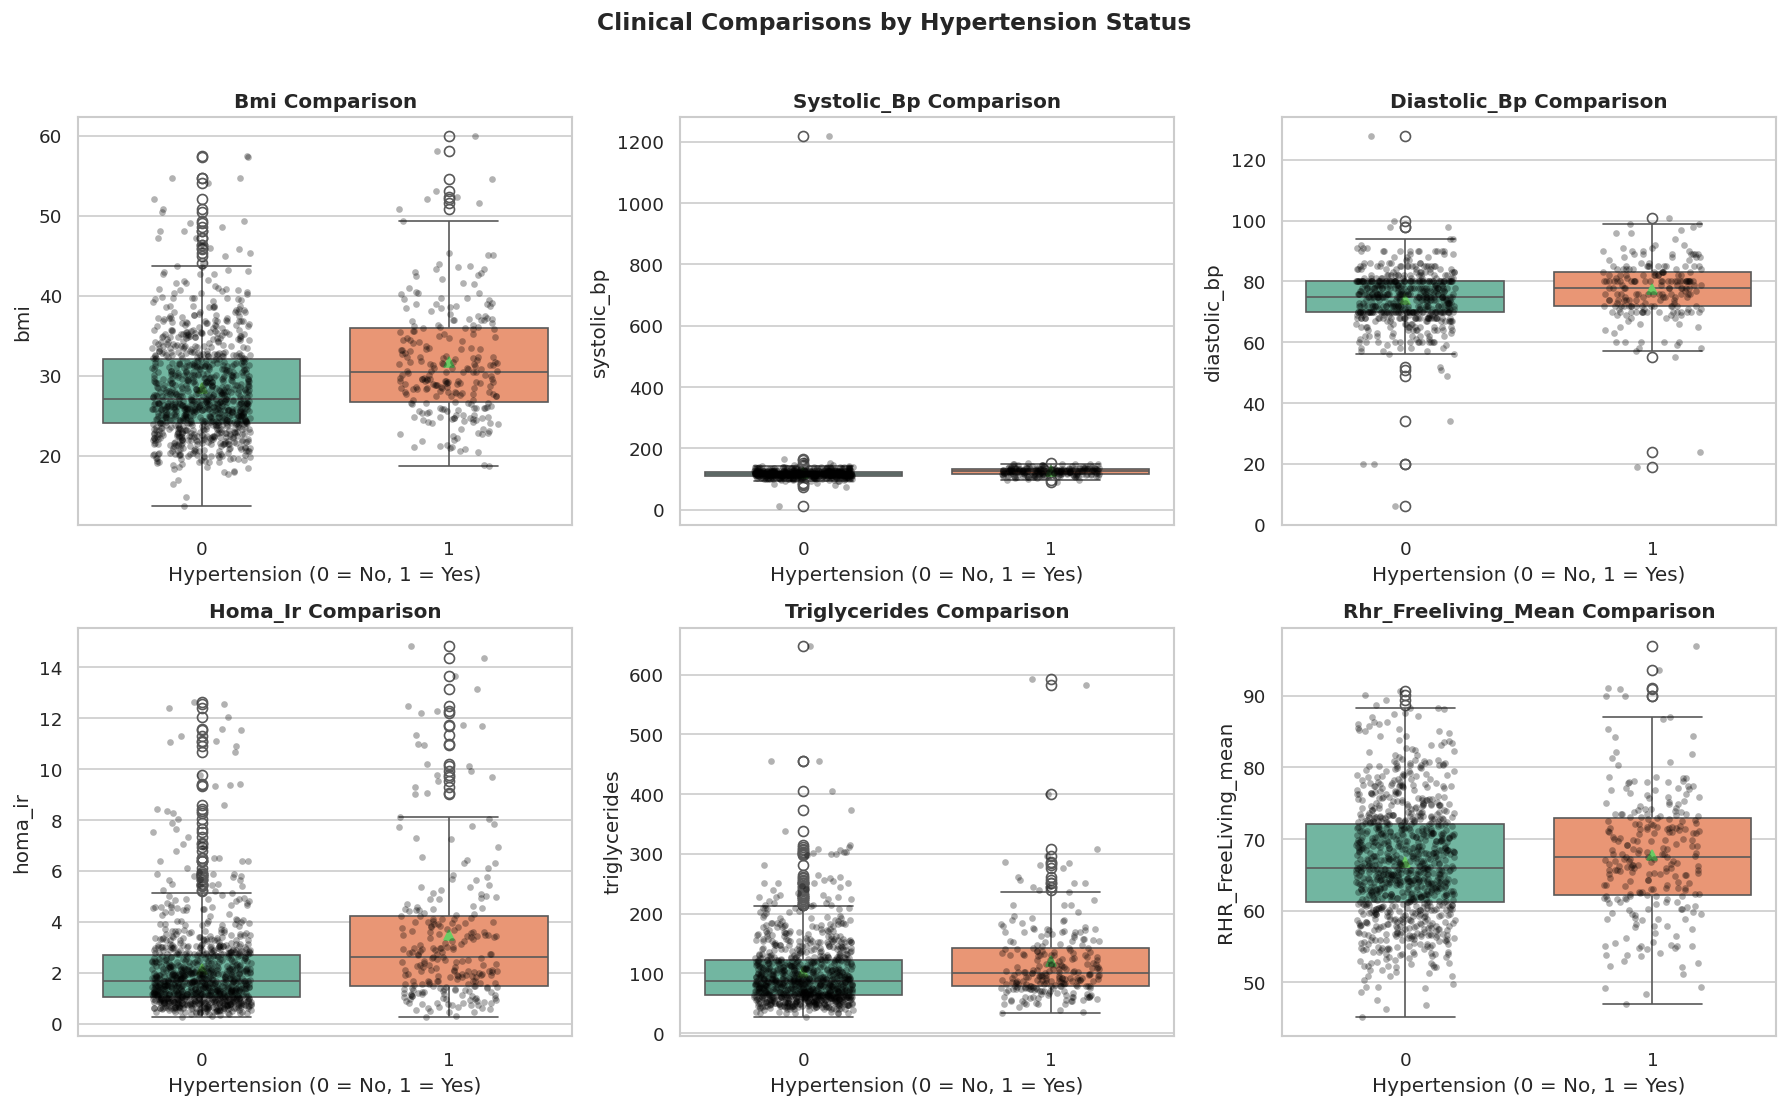

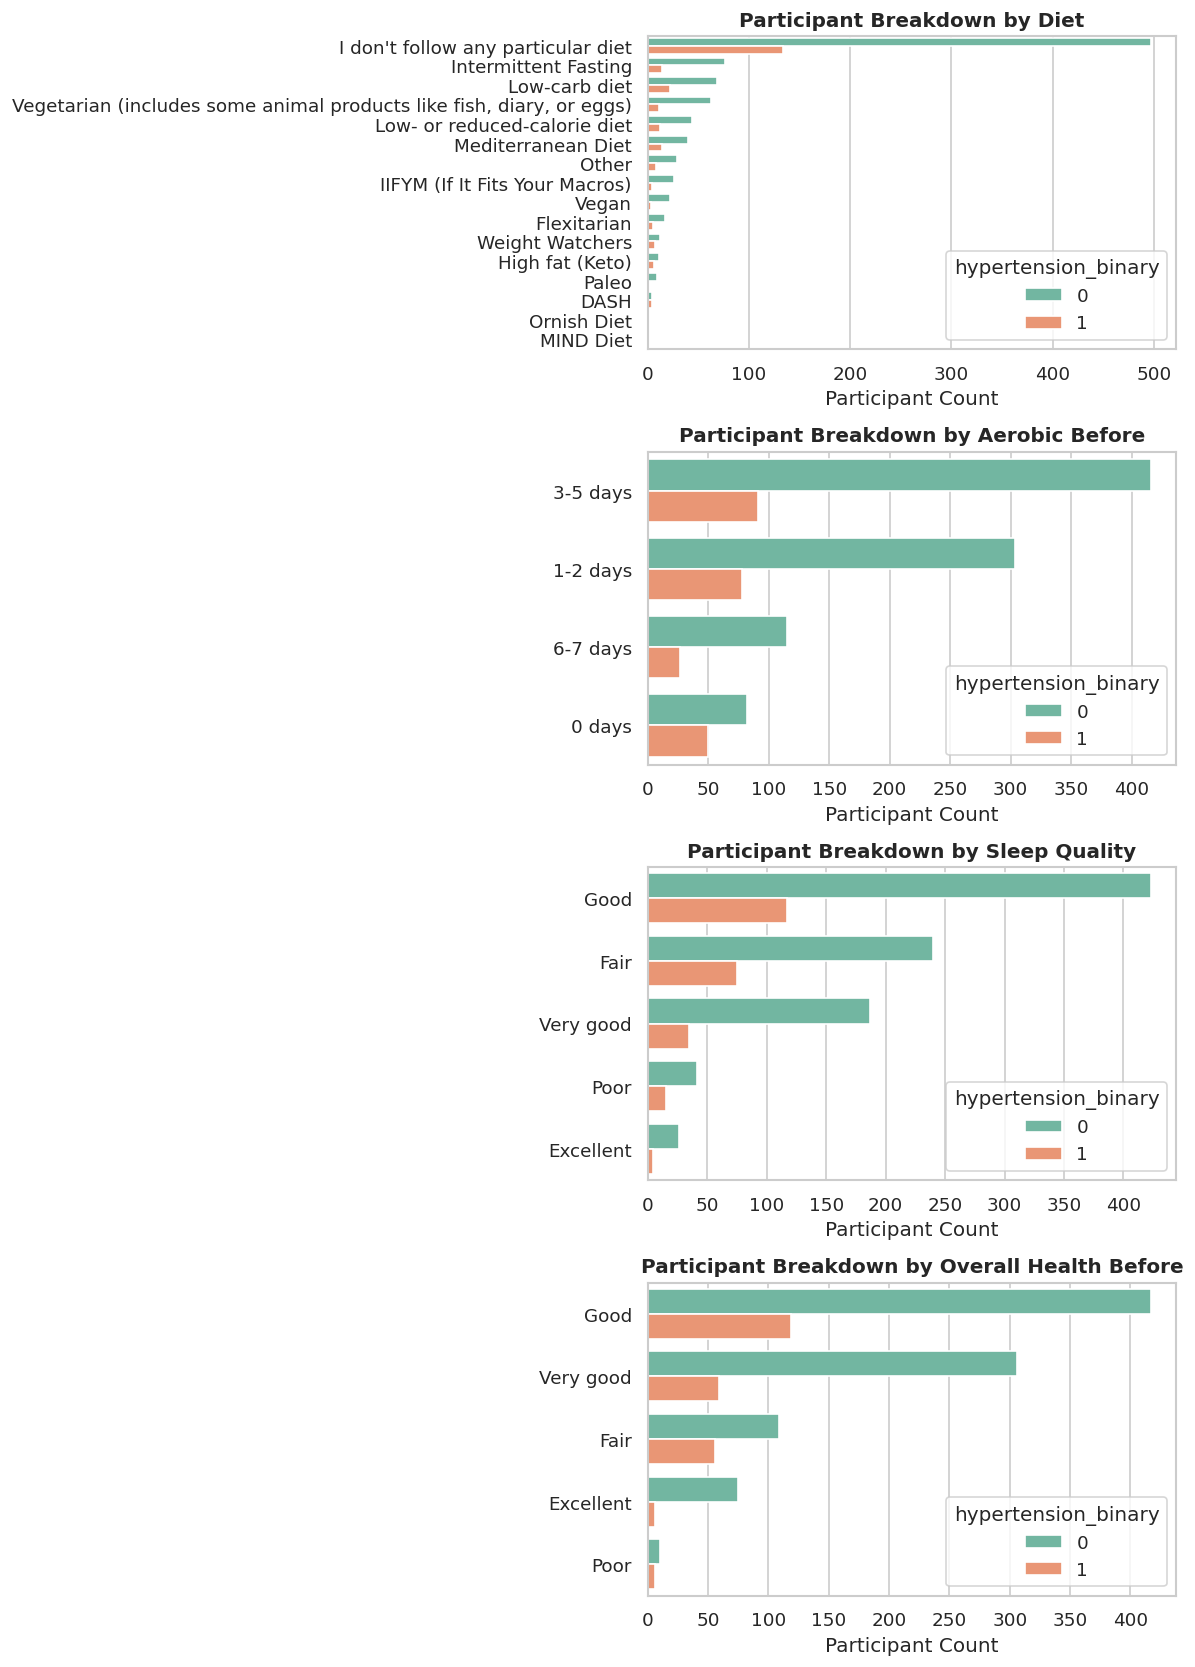

In [2]:
# ==============================================================================
# 1. Environment Setup & Data Ingestion
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

# Load Parquet datasets
df_data = pd.read_parquet('data.pq')
df_ir = pd.read_parquet('ir_prediction_data.pq')

print(f"data.pq loaded successfully: {df_data.shape[0]} rows, {df_data.shape[1]} columns.")
print(f"ir_prediction_data.pq loaded successfully: {df_ir.shape[0]} rows, {df_ir.shape[1]} columns.")

# ==============================================================================
# 2. Target Class Distribution (Hypertension)
# ==============================================================================
if 'hypertension_binary' in df_ir.columns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    # Case counts
    sns.countplot(data=df_ir, x='hypertension_binary', palette='Set2', ax=ax1)
    ax1.set_title('Hypertension Case Counts', fontweight='bold', fontsize=12)
    ax1.set_xlabel('Hypertension (0 = No, 1 = Yes)')
    ax1.set_ylabel('Participant Count')
    for p in ax1.patches:
        ax1.annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

    # Percentage proportion
    counts = df_ir['hypertension_binary'].value_counts()
    ax2.pie(counts, labels=['Non-Hypertensive (0)', 'Hypertensive (1)'], autopct='%1.1f%%',
            colors=sns.color_palette('Set2')[:2], startangle=90, explode=(0.03, 0.03))
    ax2.set_title('Hypertension Proportion', fontweight='bold', fontsize=12)

    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. Continuous Wearable Metrics (Fitbit)
# ==============================================================================
wearable_cols = ['RHR_FreeLiving_mean', 'HRV_FreeLiving_mean', 'STEPS_Daily_mean', 'SLEEP_Duration_mean']
avail_w = [c for c in wearable_cols if c in df_ir.columns]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
titles = ['Resting Heart Rate (bpm)', 'Heart Rate Variability (ms)', 'Daily Step Count', 'Sleep Duration (hrs)']
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b0']

for i, col in enumerate(avail_w):
    sns.histplot(df_ir[col], kde=True, ax=axes[i], color=colors[i % len(colors)], edgecolor='none', alpha=0.6)
    axes[i].set_title(titles[i], fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle('Distribution of Continuous Wearable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. Metabolic & Lipid Biomarkers Density Visualizations
# ==============================================================================
lipid_cols = ['total cholesterol', 'triglycerides', 'hdl', 'ldl', 'glucose', 'hba1c', 'homa_ir']
avail_lipids = [c for c in lipid_cols if c in df_ir.columns]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(avail_lipids):
    sns.kdeplot(data=df_ir, x=col, hue='hypertension_binary' if 'hypertension_binary' in df_ir.columns else None,
                fill=True, common_norm=False, palette='Set1', ax=axes[i])
    axes[i].set_title(col.title(), fontweight='bold')
    axes[i].set_xlabel('')

# Clean up empty axes
for j in range(len(avail_lipids), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Density Distributions of Metabolic & Lipid Biomarkers', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. Correlation Heatmap across Vitals, Labs & Wearables
# ==============================================================================
corr_cols = ['RHR_FreeLiving_mean', 'HRV_FreeLiving_mean', 'STEPS_Daily_mean',
             'total cholesterol', 'triglycerides', 'glucose', 'hba1c',
             'homa_ir', 'systolic_bp', 'diastolic_bp', 'bmi', 'apri', 'hypertension_binary']
avail_corr = [c for c in corr_cols if c in df_ir.columns]

plt.figure(figsize=(11, 9))
corr_matrix = df_ir[avail_corr].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix across Wearables, Labs & Vitals', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ==============================================================================
# 6. Grouped Boxplots: Hypertensive vs. Non-Hypertensive
# ==============================================================================
comp_cols = ['bmi', 'systolic_bp', 'diastolic_bp', 'homa_ir', 'triglycerides', 'RHR_FreeLiving_mean']
avail_comp = [c for c in comp_cols if c in df_ir.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(avail_comp):
    sns.boxplot(data=df_ir, x='hypertension_binary', y=col, palette='Set2', ax=axes[i], showmeans=True)
    sns.stripplot(data=df_ir, x='hypertension_binary', y=col, color='black', alpha=0.3, jitter=0.2, size=4, ax=axes[i])
    axes[i].set_title(f'{col.title()} Comparison', fontweight='bold')
    axes[i].set_xlabel('Hypertension (0 = No, 1 = Yes)')

plt.suptitle('Clinical Comparisons by Hypertension Status', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 7. Survey Data & Lifestyle Habits
# ==============================================================================
cat_cols = ['diet', 'aerobic_before', 'sleep_quality', 'overall_health_before']
avail_cat = [c for c in cat_cols if c in df_ir.columns]

fig, axes = plt.subplots(len(avail_cat), 1, figsize=(10, 3.5 * len(avail_cat)))
if len(avail_cat) == 1:
    axes = [axes]

for i, col in enumerate(avail_cat):
    sns.countplot(data=df_ir, y=col, hue='hypertension_binary' if 'hypertension_binary' in df_ir.columns else None,
                  palette='Set2', ax=axes[i], order=df_ir[col].value_counts().index)
    axes[i].set_title(f'Participant Breakdown by {col.replace("_", " ").title()}', fontweight='bold')
    axes[i].set_xlabel('Participant Count')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

# New Section